# Network schematic

In [1]:
import os
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Circle
import healpy as hp

pl = plt
HERE = Path.cwd()
def _find_data():
    """NN4R_DATA if set; otherwise the bundle layout (../final_paper_data) or the
    original working layout (../../current_version_result_data_and_plotter/final_paper_data)."""
    if os.environ.get('NN4R_DATA'):
        return Path(os.environ['NN4R_DATA']).resolve()
    for cand in [HERE.parent / 'final_paper_data',
                 HERE.parent.parent / 'current_version_result_data_and_plotter' / 'final_paper_data']:
        if (cand / 'inventory.json').is_file():
            return cand.resolve()
    raise FileNotFoundError('final_paper_data not found; set NN4R_DATA')
DATA = _find_data()
FIG = HERE.parent / 'figures'; FIG.mkdir(exist_ok=True)

with np.load(DATA / '01_simulations/example_six_band_maps.npz') as z:
    MAPS = z['fg']; PIX = z['pixels'].astype(int); OBS = z['observed'].astype(bool)
    NSIDE = int(z['nside']); BANDS = list(z['bands'].astype(int))
NPIX = hp.nside2npix(NSIDE)
print('six-band FG realization:', MAPS.shape, 'Nside', NSIDE)

# graph support: observed + zero-padding pixels (NESTED), the nodes of the input graph
SELECTED = np.zeros(NPIX); SELECTED[PIX] = 1.0
ROT = (0, -62, 0)   # view centred south of the patch so that it fills the upper part of each disc

six-band FG realization: (6, 99328) Nside 128


In [2]:
def add_dots_vertical(args_scatter={}):
    pl.scatter([2, 2, 2], [1, 2, 3], **args_scatter)
    pl.ylim(0, 4); pl.xlim(0, 4); pl.gca().axis('off')


def add_filter_stack(coeffs, args_plot={}):
    def add_filled_rect(dc, c, zorder, color='w'):
        pl.fill_between([-c - dc, c - dc], [c - dc, c - dc], [-c - dc, -c - dc], zorder=zorder, color=color)
        for xs, ys in [([-c - dc, -c - dc], [-c - dc, c - dc]), ([c - dc, c - dc], [-c - dc, c - dc]),
                       ([-c - dc, c - dc], [-c - dc, -c - dc]), ([c - dc, -c - dc], [c - dc, c - dc])]:
            pl.plot(xs, ys, c='k', lw=1, zorder=zorder)
    x = np.linspace(-2, 2, 100)
    y = np.exp(-x**2 / 2.) * np.polynomial.chebyshev.Chebyshev(coeffs)(x)
    y -= y.min(); y /= y.max(); y = 4 * y - 2
    c, dc = 2 * 1.2, 0.3
    for k, col in enumerate(['white', 'lightgray', 'white', 'lightgray', 'white']):
        add_filled_rect(dc=k * dc, c=c, zorder=5 - k, color=col)
    pl.plot(x, y, zorder=10, **args_plot)
    pl.ylim(-c - 4 * dc * 1.1 - 1, c * 1.05); pl.xlim(-c - 4 * dc * 1.1 - 1, c * 1.05)
    pl.plot([-c - 4 * dc * 1.1 - 1, -c - 4 * dc * 1.1 - 0.3], [-1.2, -1.2], c='k', lw=2)
    pl.gca().axis('off')


def add_first_connections():
    lw = 2; lvl0 = -0.5; lvls = [-0.5, -1.5, -2.5, -3.5]
    c1, c2, cm1, cm2 = 0.05, 0.9, 0.5, 0.7
    for l in [lvls[0], lvls[1], lvls[3]]:
        pl.plot([c1, c2], [lvl0, l], c='k', lw=lw)
    lm1 = (lvls[2] - lvl0) * ((cm1 - c1) / (c2 - c1)) + lvl0
    lm2 = (lvls[2] - lvl0) * ((cm2 - c1) / (c2 - c1)) + lvl0
    pl.plot([c1, cm1], [lvl0, lm1], c='k', lw=lw)
    pl.plot([c1, cm2], [lvl0, lm2], c='k', lw=lw, ls=':')
    pl.ylim(-4, 0); pl.xlim(0, 1); pl.gca().axis('off')


def _sum_nodes(c2, lvls, lw):
    pl.scatter([c2] * 3, [lvls[0], lvls[1], lvls[3]], s=500, zorder=100, c='w', lw=lw, edgecolor='k')
    pl.scatter([c2] * 3, [lvls[0], lvls[1], lvls[3]], marker='+', s=150, zorder=101, c='k', lw=2)


def add_second_connections():
    lw = 2; lvls = [-0.5, -1.5, -2.5, -3.5]
    c1, c2, cm1, cm2 = 0.05, 0.9, 0.3, 0.35
    for lvl0 in [-1.5, -0.5, -3.5]:
        for l in [lvls[0], lvls[1], lvls[3]]:
            pl.plot([c1, c2], [lvl0, l], c='k', lw=lw)
        lm1 = (lvls[2] - lvl0) * (cm1 / (c2 - c1)) + lvl0
        lm2 = (lvls[2] - lvl0) * (cm2 / (c2 - c1)) + lvl0
        pl.plot([c1, c1 + cm1], [lvl0, lm1], c='k', lw=lw); pl.plot([c1, c1 + cm2], [lvl0, lm2], c='k', lw=lw, ls=':')
        pl.plot([c2 - cm1, c2], [lm1, lvl0], c='k', lw=lw); pl.plot([c2 - cm2, c2], [lm2, lvl0], c='k', lw=lw, ls=':')
    _sum_nodes(c2, lvls, lw)
    pl.ylim(-4, 0); pl.xlim(0, 1); pl.gca().axis('off')


def add_third_connections():
    lw = 2; lvls = [-0.5, -1.5, -2.5, -3.5]
    c1, c2, cm1, cm2 = 0.05, 0.9, 0.2, 0.35
    for lvl0 in [-1.5, -0.5, -3.5]:
        for l in lvls:
            lm1 = (l - lvl0) * (cm1 / (c2 - c1)) + lvl0
            lm2 = (l - lvl0) * (cm2 / (c2 - c1)) + lvl0
            pl.plot([c1, c1 + cm1], [lvl0, lm1], c='k', lw=lw); pl.plot([c1, c1 + cm2], [lvl0, lm2], c='k', lw=lw, ls=':')
            pl.plot([c2 - cm1, c2], [lm1, lvl0], c='k', lw=lw); pl.plot([c2 - cm2, c2], [lm2, lvl0], c='k', lw=lw, ls=':')
    _sum_nodes(c2, lvls, lw)
    pl.ylim(-4, 0); pl.xlim(0, 1); pl.gca().axis('off')


def add_fully_connected():
    def rect(x1, x2, y1, y2, color, lw=2):
        pl.fill_between([x1, x2], [y1, y1], [y2, y2], zorder=10, color=color)
        for xs, ys in [([x1, x2], [y1, y1]), ([x1, x2], [y2, y2]), ([x1, x1], [y1, y2]), ([x2, x2], [y1, y2])]:
            pl.plot(xs, ys, c='k', lw=lw, zorder=10)
    lw, ss = 2, 400
    r1, r2 = 0.1, 3.9
    x1, x2, x3, x4, x5 = 0.1, 0.15, 0.3, 0.5, 0.7
    lvl1, lvl2, lvl3 = 1, 3, 2.5
    o1, o2 = 1.8, 2.2
    # pooled feature vector: mean | variance | maximum
    rect(x1, x2, r1, 1.37, '#e5f0f8'); rect(x1, x2, 1.37, 2.63, 'white'); rect(x1, x2, 2.63, r2, '#e5f0f8')
    pl.plot([x2, x3], [r1, lvl1], c='k', lw=lw); pl.plot([x2, x3], [r2, lvl2], c='k', lw=lw)
    pl.scatter([x3] * 3, [lvl1, lvl2, lvl3], c='w', s=ss, edgecolor='k', lw=lw, zorder=100)
    pl.scatter([x4] * 3, [lvl1, lvl2, lvl3], c='w', s=ss, edgecolor='k', lw=lw, zorder=100)
    for a in [lvl1, lvl2, lvl3]:
        for b in [lvl1, lvl2, lvl3]:
            pl.plot([x3, x4], [a, b], c='k', lw=lw)
    pl.scatter([x5, x5], [o1, o2], s=ss, c='w', edgecolor='k', lw=lw, zorder=100)
    for a in [lvl1, lvl2, lvl3]:
        for b in [o1, o2]:
            pl.plot([x4, x5], [a, b], c='k', lw=lw)
    pl.plot([x4, x4], [1.5, 2.], ':', c='k'); pl.plot([x3, x3], [1.5, 2.], ':', c='k')
    pl.plot([x1 - 0.05, x1], [r1, r1], c='k', lw=lw); pl.plot([x1 - 0.05, x1], [r2, r2], c='k', lw=lw)
    pl.text(x5 + 0.05, o2, r'$\mu$', fontsize=22, va='center')
    pl.text(x5 + 0.05, o1, r'$\log\sigma^2$', fontsize=22, va='center')
    pl.ylim(-0.5, 4.5); pl.xlim(0, 0.95); pl.gca().axis('off')


def add_text(text_str, ypos=0.9, fontsize=25, weight='normal'):
    pl.text(x=0, y=ypos, s=text_str, ha='center', va='center', fontsize=fontsize, weight=weight)
    pl.ylim(-1, 1); pl.xlim(-1, 1); pl.gca().axis('off')


VIEW = hp.ang2vec(ROT[0], ROT[1], lonlat=True)   # line-of-sight of the orthographic view


def make_graph_ball(nside_low):
    """Schematic of the pooled graph: the padded footprint at a coarse resolution,
    one marker per graph node (pixel centre) on the visible hemisphere."""
    sel = hp.ud_grade(SELECTED, nside_low, order_in='NESTED', order_out='NESTED') > 0
    values = np.where(sel, np.arange(len(sel)) / len(sel), hp.UNSEEN)
    hp.visufunc.orthview(map=values, half_sky=True, title='', rot=ROT, cmap=mpl.colormaps['viridis_r'],
                         cbar=False, hold=True, nest=True, min=-0.5, max=1.5, badcolor='0.55', notext=True)
    pix = np.where(sel)[0]
    vec = np.array(hp.pix2vec(nside_low, pix, nest=True)).T
    pix = pix[vec @ VIEW > 0.12]            # only nodes well inside the visible disc
    th, ph = hp.pix2ang(nside_low, pix, nest=True)
    x, y = plt.gca().proj.ang2xy(th, ph)
    pl.scatter(x, y, s=10, c='k', zorder=5); pl.gca().axis('off')

In [3]:
def draw_input_stack(fig, region, dxi=0.38, dyi=1.0, margin=1.25):
    """Six orthographic views stacked like cards: 27 GHz at the back (top-left),
    280 GHz in front (bottom-right) and fully visible.

    region = (x0, y0, w, h) in figure coordinates of the area reserved for the stack.
    """
    x0, y0, w, h = region
    n = len(BANDS)
    fw, fh = fig.get_size_inches()
    # offsets in inches; disc diameter chosen so the stack fills the region
    d = min(w * fw - margin - (n - 1) * dxi, h * fh - (n - 1) * dyi)
    for i in range(n):
        left = x0 * fw + margin + i * dxi
        bottom = (y0 + h) * fh - d - i * dyi
        ax = fig.add_axes([left / fw, bottom / fh, d / fw, d / fh])
        values = MAPS[i]
        full = np.full(NPIX, hp.UNSEEN); full[PIX[OBS]] = values[OBS]
        plt.sca(ax)
        hp.orthview(full, nest=True, rot=ROT, half_sky=True, hold=True, title='', cbar=False, notext=True,
                    cmap=mpl.colormaps['RdBu_r'], norm='hist', badcolor='0.8')
        ax = plt.gca()
        ax.set_xlim(-1.0, 1.0); ax.set_ylim(-1.0, 1.0); ax.set_aspect('equal')
        ax.patch.set_alpha(0.0)
        disc = Circle((0, 0), 1.0, transform=ax.transData)
        for im in ax.images:
            im.set_clip_path(disc)
        ax.add_patch(Circle((0, 0), 1.0, transform=ax.transData, fill=False, ec='k', lw=1.4, zorder=20,
                            clip_on=False))
        ax.axis('off')
        # band label to the left of the visible top strip of each card
        label_y = bottom + d - (0.5 * dyi if i < n - 1 else 0.55 * d)
        fig.text((x0 * fw + margin - 0.15) / fw, label_y / fh, f'{BANDS[i]} GHz', ha='right', va='center', fontsize=17)

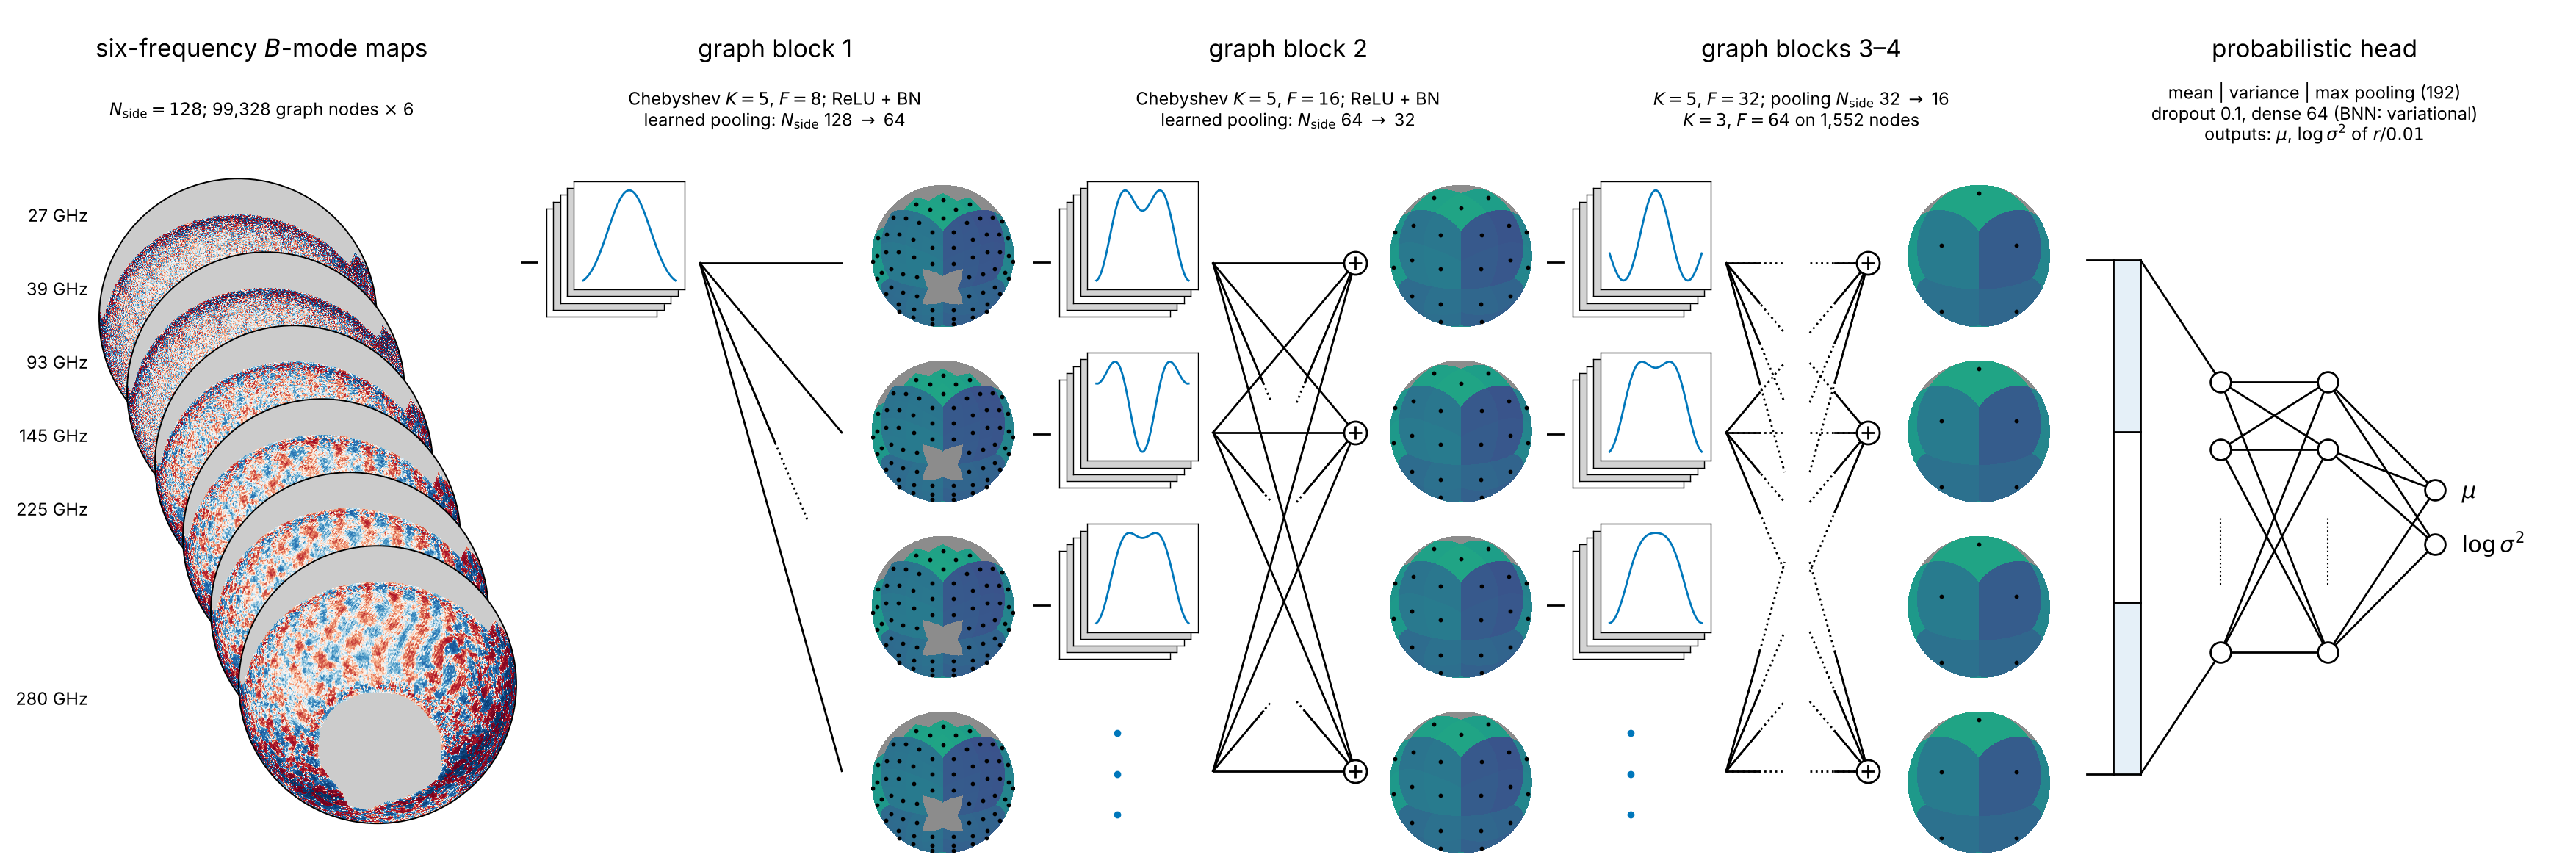

saved network_architecture


In [4]:
FILTERS = [np.array([11.25365034, 0., -1.18938064, 0., -0.05086713, 0.]),
           np.array([-9.78160805, 0., -1.42653875, 0., -1.38142099, 0.]),
           np.array([-18.02216716, 0., 0.94142343, 0., -0.84953354, 0.]),
           np.array([-0.66255557, 0., -0.69860735, 0., -0.4712247, 0.]),
           np.array([-1.04785434, 0., -0.88448022, 0., -0.0026601, 0.]),
           np.array([0.43662062, 0., -1.45210374, 0., -1.74437622, 0.]),
           np.array([2.25798642, 0., -5.75147804, 0., -1.29044244, 0.])]
FCOL = dict(c='#0077BB', lw=2)

nr, nc, psr, psc, dr = 5, 15, 3, 3, 1
fig = pl.figure(figsize=(nc * psc, nr * psr))
gs = gridspec.GridSpec(nr, nc)

ax = plt.subplot(gs[0, 0:3])
add_text('six-frequency $B$-mode maps', ypos=0.5, fontsize=24)
add_text('$N_{\\rm side}=128$; 99,328 graph nodes $\\times$ 6', ypos=-0.25, fontsize=17)

# graph block 1: Nside 128 -> 64
ax = plt.subplot(gs[dr, 3]); add_filter_stack(FILTERS[0], FCOL)
ax = plt.subplot(gs[dr:, 4]); add_first_connections()
for irow in range(4):
    ax = plt.subplot(gs[irow + dr, 5]); make_graph_ball(4)

# graph block 2: Nside 64 -> 32
for irow, k in enumerate([1, 2, 3]):
    ax = plt.subplot(gs[irow + dr, 6]); add_filter_stack(FILTERS[k], FCOL)
ax = plt.subplot(gs[3 + dr, 6]); add_dots_vertical(dict(c='#0077BB'))
ax = plt.subplot(gs[dr:, 7]); add_second_connections()
for irow in range(4):
    ax = plt.subplot(gs[irow + dr, 8]); make_graph_ball(2)

# graph blocks 3-4: Nside 32 -> 16
for irow, k in enumerate([4, 5, 6]):
    ax = plt.subplot(gs[irow + dr, 9]); add_filter_stack(FILTERS[k], FCOL)
ax = plt.subplot(gs[3 + dr, 9]); add_dots_vertical(dict(c='#0077BB'))
ax = plt.subplot(gs[dr:, 10]); add_third_connections()
for irow in range(4):
    ax = plt.subplot(gs[irow + dr, 11]); make_graph_ball(1)

# summary statistics and probabilistic head
ax = plt.subplot(gs[dr:, 12:15]); add_fully_connected()

ax = plt.subplot(gs[0, 3:6])
add_text('graph block 1', ypos=0.5, fontsize=24)
add_text('Chebyshev $K=5$, $F=8$; ReLU + BN\nlearned pooling: $N_{\\rm side}$ 128 $\\to$ 64', ypos=-0.25, fontsize=17)
ax = plt.subplot(gs[0, 6:9])
add_text('graph block 2', ypos=0.5, fontsize=24)
add_text('Chebyshev $K=5$, $F=16$; ReLU + BN\nlearned pooling: $N_{\\rm side}$ 64 $\\to$ 32', ypos=-0.25, fontsize=17)
ax = plt.subplot(gs[0, 9:12])
add_text('graph blocks 3–4', ypos=0.5, fontsize=24)
add_text('$K=5$, $F=32$; pooling $N_{\\rm side}$ 32 $\\to$ 16\n$K=3$, $F=64$ on 1,552 nodes', ypos=-0.25, fontsize=17)
ax = plt.subplot(gs[0, 12:15])
add_text('probabilistic head', ypos=0.5, fontsize=24)
add_text('mean | variance | max pooling (192)\ndropout 0.1, dense 64 (BNN: variational)\noutputs: $\\mu$, $\\log\\sigma^2$ of $r/0.01$',
         ypos=-0.3, fontsize=17)

plt.subplots_adjust(wspace=0.025, hspace=0.05)
box = gs[1:5, 0:3].get_position(fig)
draw_input_stack(fig, (box.x0, box.y0, box.width, box.height))
fig.savefig(FIG / 'network_architecture.pdf', bbox_inches='tight', facecolor='white')
fig.savefig(FIG / 'network_architecture.png', bbox_inches='tight', facecolor='white', dpi=80)
plt.show()
print('saved network_architecture')